# 17 · Embeddings and rerankers: the retrieval layer, measured

Every RAG system (notebook 18), semantic search box, recommender (notebook 23) and agent memory (notebook 25) starts with the same question: *which few documents, out of thousands or millions, are relevant to this query?* The answer is almost always a pipeline of two kinds of models: an **embedding model** that turns text into vectors you can search, and a **reranker** that reads the best candidates more carefully. This notebook takes both apart on a real retrieval benchmark and measures every decision you make when you build one:

| question | measured here |
|---|---|
| which off-the-shelf model? | BM25 vs three embedding models, with and without task prefixes |
| how are embedding models trained, and does fine-tuning pay? | InfoNCE by hand; contrastive fine-tuning on 809 labelled queries, with and without hard negatives; what it does to a *different* domain |
| how small can the vectors be? | Matryoshka training vs plain truncation; int8 and binary quantization with rescoring; memory per million documents |
| what does a reranker add, and at what latency? | hybrid BM25 + dense retrieval, then two cross-encoders at different depths |

Read it **before notebook 18**: RAG builds on these components, and this notebook shows how to choose and tune them.

**Sources.** Alammar and Grootendorst, *Hands-On Large Language Models*, ch. 8 (semantic search and RAG) and ch. 10 (creating text embedding models); Huyen, *AI Engineering*, ch. 6 (retrieval); Stanford CME 295, retrieval-augmented generation.

## Background: how a text becomes a vector you can search

### Three ways to score a query against a document

| architecture | how it scores | cost at query time | quality | examples |
|---|---|---|---|---|
| **bi-encoder** (embedding model) | encode query and document *separately* into vectors; score = cosine similarity | one forward pass for the query, then a vector search over precomputed document vectors | good | all-MiniLM, BGE, E5, GTE, nomic-embed, OpenAI `text-embedding-3` |
| **cross-encoder** (reranker) | feed query and document *together* through one transformer; a head outputs a relevance score | one forward pass **per candidate document** | best | `ms-marco-MiniLM`, `bge-reranker`, Cohere Rerank, Jina reranker |
| **late interaction** | keep one vector per token; score = sum over query tokens of the best-matching document token (MaxSim) | vector search over token vectors | between the two | ColBERT, ColPali |

The bi-encoder is fast because the expensive part (encoding 5,000 or 5 billion documents) happens once, offline. The price is that the query and the document never see each other: everything the model knows about a document must fit in one vector before it knows what will be asked. A cross-encoder lets every query token attend to every document token (the full attention of notebook 03), which is why it is more accurate and why it is too slow to run over a whole corpus. Production search therefore uses both, in the **retrieve-then-rerank** funnel, the same one the recommender of notebook 23 uses: a cheap first stage (BM25, embeddings or both) returns 50–100 candidates, and a cross-encoder reorders them.

### How embedding models are trained: contrastive learning

An embedding model is an encoder (notebook 06) with a pooling step (mean of the token vectors, or the `[CLS]` vector), trained so that a query lands near its relevant documents and far from the rest. The standard loss is **InfoNCE** (van den Oord et al., 2018), with **in-batch negatives**: in a batch of $B$ (query, positive document) pairs, every other document in the batch serves as a negative for each query.

$$\mathcal{L} = -\frac{1}{B}\sum_{i=1}^{B} \log \frac{\exp(\mathrm{sim}(q_i, d_i)/\tau)}{\sum_{j=1}^{B} \exp(\mathrm{sim}(q_i, d_j)/\tau)}$$

It is a cross-entropy over the batch: the "class" of query $i$ is its own document. Three details matter in practice:

- **Temperature** $\tau$ (often 0.01–0.05): cosine similarities live in $[-1, 1]$, and dividing by a small $\tau$ makes the softmax sharp enough to learn from. `sentence-transformers` calls this loss `MultipleNegativesRankingLoss` and writes it as a `scale` of $1/\tau = 20$.
- **Batch size**: more in-batch negatives make the task harder and the embeddings better, which is why embedding models are trained with batches of thousands (CLIP used 32,768), and why tricks such as GradCache exist.
- **Hard negatives**: random negatives are easy. Mining documents that BM25 or an earlier model ranks high but that are *not* relevant gives the model the cases that actually confuse it, the main ingredient of DPR (Karpukhin et al., 2020) and of every modern recipe.

Modern models (E5, BGE, GTE, nomic-embed) are trained in two stages: weakly supervised contrastive pre-training on hundreds of millions of naturally paired texts (title–body, question–answer, query–click), then fine-tuning on smaller labelled sets with hard negatives. Many are also *asymmetric*: they expect a **task prefix** such as `search_query:` / `search_document:` (nomic) or `query:` / `passage:` (E5), because a short question and a long passage are different kinds of text. Forgetting the prefix is one of the most common silent bugs; we measure its cost.

### Matryoshka embeddings and quantization: making vectors cheaper

A corpus of 100 million documents with 768 float32 dimensions takes 300 GB of RAM. Two independent ideas shrink it.

- **Matryoshka Representation Learning** (Kusupati et al., 2022) trains the model so that the *first* $m$ dimensions of every vector are themselves a good embedding, by summing the contrastive loss over several prefixes (768, 512, 256, 128, 64). You can then truncate vectors after the fact and trade quality for memory. OpenAI's `text-embedding-3` (`dimensions=`), nomic-embed v1.5 and many recent models are trained this way. A model trained *without* it has no reason to put the important information first, and truncation hurts it much more; we compare both.
- **Quantization**: store each dimension in int8 (4× smaller) or as a single sign bit (**binary**, 32× smaller, compared with Hamming distance, which CPUs compute with one instruction). The standard recipe is to retrieve with the cheap codes and then **rescore** the top candidates with the float vectors, which recovers most of the lost quality.

### How retrieval quality is measured

We use the evaluation of the BEIR benchmark (Thakur et al., 2021), on which most embedding leaderboards (MTEB) are built:

- **nDCG@10** (normalized discounted cumulative gain): a relevant document at rank $r$ earns $1/\log_2(r+1)$, and the sum is divided by the best possible score for that query. It rewards putting relevant documents *first*, and it is the headline metric of BEIR and MTEB retrieval.
- **Recall@100**: the share of relevant documents found in the top 100. It is what a reranker can work with: a document the first stage misses can never be reranked to the top.

Leaderboards are a starting point, not an answer: MTEB averages dozens of tasks, scores on public sets can be inflated by training on them, and the only number that decides is the one on *your* queries and documents. That is what this notebook practises, on **SciFact** (Wadden et al., 2020): 5,183 scientific abstracts and 300 test claims ("0-dimensional biomaterials lack inductive properties") whose supporting or refuting abstracts were labelled by experts. It also has 809 training claims, which we use to fine-tune.

### Key papers

- Reimers & Gurevych (2019), *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*.
- van den Oord, Li & Vinyals (2018), *Representation Learning with Contrastive Predictive Coding* (InfoNCE).
- Karpukhin et al. (2020), *Dense Passage Retrieval for Open-Domain Question Answering* (DPR).
- Khattab & Zaharia (2020), *ColBERT: Efficient and Effective Passage Search via Contextualized Late Interaction over BERT*.
- Nogueira & Cho (2019), *Passage Re-ranking with BERT* (the cross-encoder reranker).
- Thakur et al. (2021), *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models*.
- Muennighoff et al. (2023), *MTEB: Massive Text Embedding Benchmark*.
- Wang et al. (2022), *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5).
- Kusupati et al. (2022), *Matryoshka Representation Learning*.
- Nussbaum et al. (2024), *Nomic Embed: Training a Reproducible Long Context Text Embedder*.

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-21-embeddings")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : off (add LANGSMITH_API_KEY to .env to enable)


In [2]:
import re, gc
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"      # Windows without developer mode: the cache still works
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging; hf_logging.set_verbosity_error()
import torch, torch.nn.functional as F
import datasets, transformers
from datasets import load_dataset, Dataset
from rank_bm25 import BM25Okapi
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder, losses
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff
datasets.disable_progress_bars(); transformers.utils.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device", device, "| sentence-transformers", sentence_transformers.__version__)

def free():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

W1109 20:07:07.193000 14140 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


device cuda | sentence-transformers 6.2.0


## 1. The data and the metrics

SciFact comes from the BEIR collection on the Hugging Face Hub (`mteb/scifact`). Each document is a title and an abstract; each query is a scientific claim; the relevance labels (*qrels*) say which abstracts support or refute it. We also load **NFCorpus** (nutrition and medicine questions against PubMed articles, graded relevance), used only in section 3 to check what fine-tuning does to a domain the model was not tuned on.

The metrics are written out in a few lines: nDCG@10 with graded gains (SciFact's labels are all 1, so there it is the binary version), and recall@100. We keep the per-query values, because every comparison below comes with a paired bootstrap interval over queries.

In [3]:
def load_beir(name):
    corpus = load_dataset(f"mteb/{name}", "corpus", split="corpus")
    qd = load_dataset(f"mteb/{name}", "queries", split="queries")
    queries = dict(zip(qd["_id"], qd["text"]))
    def qrels(split):
        rel = {}
        for r in load_dataset(f"mteb/{name}", "default", split=split):
            if r["score"] > 0:
                rel.setdefault(r["query-id"], {})[r["corpus-id"]] = r["score"]
        return rel
    ids = corpus["_id"]
    docs = [(t + ". " + x).strip() for t, x in zip(corpus["title"], corpus["text"])]
    in_corpus = set(ids)
    test = {q: {d: g for d, g in rel.items() if d in in_corpus} for q, rel in qrels("test").items()}
    test = {q: rel for q, rel in test.items() if rel}          # drop queries whose relevant documents are all missing
    qids = sorted(test)
    return {"name": name, "ids": ids, "pos": {d: i for i, d in enumerate(ids)}, "docs": docs, "queries": queries,
            "qids": qids, "qtexts": [queries[q] for q in qids], "test": test,
            "train": qrels("train") if name == "scifact" else None}

sci, nfc = load_beir("scifact"), load_beir("nfcorpus")
for ds in (sci, nfc):
    print(f"{ds['name']:9s} {len(ds['docs']):5d} documents | {len(ds['qids'])} test queries | "
          f"{np.mean([len(v) for v in ds['test'].values()]):.1f} relevant documents per query | "
          f"{np.mean([len(d.split()) for d in ds['docs']]):.0f} words per document")
print(f"scifact training split: {len(sci['train'])} queries, {sum(len(v) for v in sci['train'].values())} (query, relevant document) pairs")
q0 = sci["qids"][0]
print("\nexample query:", sci["queries"][q0])
print("a relevant document:", sci["docs"][sci["pos"][next(iter(sci["test"][q0]))]][:300], "...")

def per_query(top, ds):
    """nDCG@10 and recall@100 for every test query, from a (queries x >=100) array of document positions."""
    nd, rc = [], []
    for q, row in zip(ds["qids"], top):
        gains = {ds["pos"][d]: g for d, g in ds["test"][q].items()}
        dcg = sum(gains.get(int(d), 0) / np.log2(r + 2) for r, d in enumerate(row[:10]))
        idcg = sum(g / np.log2(r + 2) for r, g in enumerate(sorted(gains.values(), reverse=True)[:10]))
        nd.append(dcg / idcg)
        rc.append(len(set(gains) & set(int(d) for d in row[:100])) / len(gains))
    return np.array(nd), np.array(rc)

RUNS = {}                       # name -> per-query nDCG@10 and recall@100, plus cost notes
def report(name, top, ds=sci, **notes):
    nd, rc = per_query(top, ds)
    RUNS[(ds["name"], name)] = {"ndcg": nd, "recall": rc, "top": top, **notes}
    m, lo, hi = bootstrap_ci(nd)
    extra = " | ".join(f"{k} {v}" for k, v in notes.items())
    print(f"{ds['name']:8s} {name:40s} nDCG@10 {m:.3f} [{lo:.3f}, {hi:.3f}] | recall@100 {rc.mean():.3f}" + (f" | {extra}" if extra else ""))

def search(Q, D, k=100):
    """Exact (brute-force) cosine search: Q and D are L2-normalized. FAISS or a vector database does the same at scale."""
    Q, D = torch.as_tensor(Q, device=device).float(), torch.as_tensor(D, device=device).float()
    return torch.topk(Q @ D.T, k, dim=1).indices.cpu().numpy()

scifact    5183 documents | 300 test queries | 1.1 relevant documents per query | 215 words per document
nfcorpus   3633 documents | 323 test queries | 38.2 relevant documents per query | 234 words per document
scifact training split: 809 queries, 919 (query, relevant document) pairs

example query: 0-dimensional biomaterials show inductive properties.
a relevant document: New opportunities: the use of nanotechnologies to manipulate and track stem cells.. Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo track ...


## 2. Off-the-shelf retrieval: BM25 and three embedding models

The candidates, from cheapest to most expensive:

- **BM25**, the lexical baseline (notebook 18): exact word overlap, weighted by rarity, with no training at all.
- **all-MiniLM-L6-v2** (22M parameters, 384 dimensions): the classic small `sentence-transformers` model, trained on a billion sentence pairs in 2021.
- **bge-small-en-v1.5** (33M, 384 dimensions, BAAI, 2023): a modern small model trained in two stages with hard negatives. Its queries take an instruction prefix.
- **nomic-embed-text v1.5** (137M, 768 dimensions), served by **Ollama**, the embedding model used by the application notebooks that run on Ollama (16, 18, 19, 23, 25, 26, 28). It expects `search_query:` / `search_document:` prefixes. We run it with and without them to measure what forgetting them costs.

scifact  BM25                                     nDCG@10 0.652 [0.608, 0.695] | recall@100 0.873 | index_s 9s


nfcorpus BM25                                     nDCG@10 0.306 [0.272, 0.341] | recall@100 0.235


scifact  all-MiniLM-L6-v2                         nDCG@10 0.648 [0.603, 0.692] | recall@100 0.925 | dim 384 | encode_corpus 10s | ms_per_query 0.3


scifact  bge-small-en-v1.5                        nDCG@10 0.706 [0.663, 0.747] | recall@100 0.943 | dim 384 | encode_corpus 43s | ms_per_query 0.8


scifact  nomic-embed-text (with prefixes)         nDCG@10 0.708 [0.666, 0.746] | recall@100 0.932 | dim 768 | encode_corpus 97s | ms_per_query 9.9


scifact  nomic-embed-text (no prefixes)           nDCG@10 0.701 [0.659, 0.740] | recall@100 0.937
  all-MiniLM-L6-v2                   vs BM25: -0.003 [-0.042, +0.032]
  bge-small-en-v1.5                  vs BM25: +0.054 [+0.015, +0.091]
  nomic-embed-text (no prefixes)     vs BM25: +0.050 [+0.011, +0.084]
  nomic-embed-text (with prefixes)   vs BM25: +0.056 [+0.021, +0.088]
  prefixes on nomic: +0.006 [-0.012, +0.022]


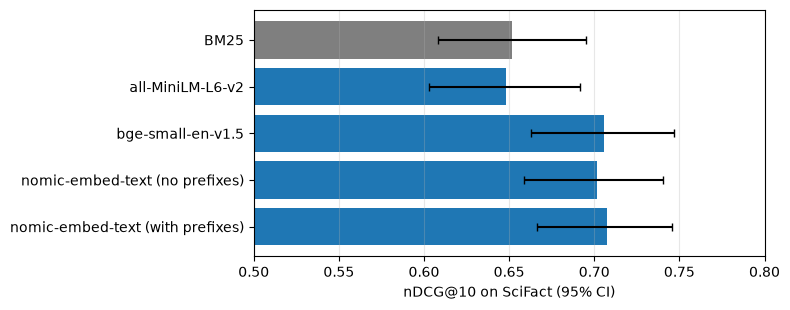

In [4]:
tok = lambda s: re.findall(r"\w+", s.lower())
t0 = time.time()
bm25 = {ds["name"]: BM25Okapi([tok(d) for d in ds["docs"]]) for ds in (sci, nfc)}
def bm25_top(ds, k=100):
    return np.array([np.argsort(-bm25[ds["name"]].get_scores(tok(q)))[:k] for q in ds["qtexts"]])
top_bm25 = bm25_top(sci)
report("BM25", top_bm25, index_s=f"{time.time() - t0:.0f}s")
report("BM25", bm25_top(nfc), ds=nfc)

def st_embed(model, ds, q_prefix="", d_prefix=""):
    t0 = time.time()
    D = model.encode([d_prefix + d for d in ds["docs"]], batch_size=64, normalize_embeddings=True)
    t_docs = time.time() - t0; t0 = time.time()
    Q = model.encode([q_prefix + q for q in ds["qtexts"]], batch_size=64, normalize_embeddings=True)
    return Q, D, t_docs, 1000 * (time.time() - t0) / len(Q)

EMB = {}       # (dataset, model) -> (Q, D), kept for the compression experiments
for name, qp in [("sentence-transformers/all-MiniLM-L6-v2", ""),
                 ("BAAI/bge-small-en-v1.5", "Represent this sentence for searching relevant passages: ")]:
    m = SentenceTransformer(name, device=device)
    Q, D, td, tq = st_embed(m, sci, q_prefix=qp)
    EMB[("scifact", name)] = (Q, D)
    report(name.split("/")[1], search(Q, D), dim=D.shape[1], encode_corpus=f"{td:.0f}s", ms_per_query=f"{tq:.1f}")
    del m; free()

emb = get_embeddings()          # nomic-embed-text through Ollama (LangChain's OllamaEmbeddings)
def ollama_embed(texts, batch=64):
    out = []
    for i in range(0, len(texts), batch):
        out += emb.embed_documents(texts[i:i + batch])
    E = np.array(out, dtype=np.float32)
    return E / np.linalg.norm(E, axis=1, keepdims=True)

t0 = time.time()
Dn = ollama_embed(["search_document: " + d for d in sci["docs"]]); td = time.time() - t0; t0 = time.time()
Qn = ollama_embed(["search_query: " + q for q in sci["qtexts"]]); tq = 1000 * (time.time() - t0) / len(Qn)
EMB[("scifact", "nomic")] = (Qn, Dn)
report("nomic-embed-text (with prefixes)", search(Qn, Dn), dim=Dn.shape[1], encode_corpus=f"{td:.0f}s", ms_per_query=f"{tq:.1f}")
report("nomic-embed-text (no prefixes)", search(ollama_embed(sci["qtexts"]), ollama_embed(sci["docs"])))

names = ["BM25", "all-MiniLM-L6-v2", "bge-small-en-v1.5", "nomic-embed-text (no prefixes)", "nomic-embed-text (with prefixes)"]
for n in names[1:]:
    d, lo, hi = paired_bootstrap_diff(RUNS[("scifact", "BM25")]["ndcg"], RUNS[("scifact", n)]["ndcg"])          # b - a: new minus baseline
    print(f"  {n:34s} vs BM25: {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")
d, lo, hi = paired_bootstrap_diff(RUNS[("scifact", names[3])]["ndcg"], RUNS[("scifact", names[4])]["ndcg"])
print(f"  prefixes on nomic: {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")

fig, ax = plt.subplots(figsize=(8, 3.2))
vals = [bootstrap_ci(RUNS[("scifact", n)]["ndcg"]) for n in names]
ax.barh(names, [v[0] for v in vals], xerr=[[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]], color=["tab:gray"] + ["tab:blue"] * 4, capsize=3)
ax.set_xlabel("nDCG@10 on SciFact (95% CI)"); ax.set_xlim(0.5, 0.8); ax.grid(alpha=.3, axis="x"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**What the numbers say.**

- **BM25 is a strong baseline here** (nDCG@10 0.652). Scientific claims share rare technical words with their abstracts ("biomaterials", "inductive"), which is exactly what BM25 rewards. The classic MiniLM model does no better (0.648, a difference of −0.003 with an interval that straddles zero).
- **The two modern models beat BM25 clearly.** bge-small reaches 0.706 (+0.054 [+0.015, +0.091]) and nomic 0.708 (+0.056 [+0.021, +0.088]). bge-small does it with half the dimensions, a quarter of the parameters and 0.8 ms per query against nomic's 9.9 ms through Ollama's HTTP API.
- **Recall@100 is where embeddings shine**: 0.925–0.943 against 0.873 for BM25. The relevant abstract is in the top 100 more often, even when it is not ranked first, and that is what a reranker needs.
- **Forgetting nomic's prefixes cost only 0.006 here** ([−0.012, +0.022], within the noise). The size of this effect depends on the model and the data: claims and abstracts look alike, while on short keyword queries against long passages the gap is usually larger. Measure it once and then always use the prefix the model card asks for.

The two modern models are statistically tied; the choice between them is about cost and serving (a 33M model in your own process, or a 137M model behind a server), not quality.

## 3. Training an embedding model: contrastive fine-tuning

### 3.1 InfoNCE by hand

Before using the library, we compute the loss from the background section by hand on a batch of 8 training pairs and check that it is exactly what `sentence-transformers`' `MultipleNegativesRankingLoss` returns. The similarity matrix makes the idea visible: each query should score its own document (the diagonal) above the other seven.

InfoNCE by hand: 0.18594 | MultipleNegativesRankingLoss: 0.18594
diagonal (query with its own document): mean cosine 0.489 | off-diagonal: 0.083
queries whose own document is the most similar in the batch: 7 of 8


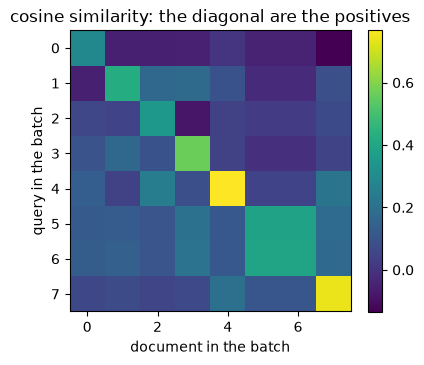

In [5]:
NAME = "sentence-transformers/all-MiniLM-L6-v2"
train_pairs = [(sci["queries"][q], sci["docs"][sci["pos"][d]]) for q, rel in sci["train"].items() for d in rel]
st = SentenceTransformer(NAME, device=device).eval()
batch = train_pairs[:8]
qs, ds_ = [q for q, _ in batch], [d for _, d in batch]

scale = 20.0                                     # 1 / temperature: sentence-transformers' default
with torch.no_grad():
    q_emb = st.encode(qs, convert_to_tensor=True, normalize_embeddings=True)
    d_emb = st.encode(ds_, convert_to_tensor=True, normalize_embeddings=True)
    sims = q_emb @ d_emb.T                       # (8, 8) cosine similarities
    by_hand = F.cross_entropy(scale * sims, torch.arange(len(batch), device=device))
    mnrl = losses.MultipleNegativesRankingLoss(st, scale=scale)
    feats = [{k: v.to(device) if torch.is_tensor(v) else v for k, v in st.preprocess(x).items()} for x in (qs, ds_)]
    library = mnrl(feats, None)
print(f"InfoNCE by hand: {by_hand.item():.5f} | MultipleNegativesRankingLoss: {library.item():.5f}")
print(f"diagonal (query with its own document): mean cosine {sims.diag().mean():.3f} | off-diagonal: {(sims.sum() - sims.diag().sum()).item() / 56:.3f}")
print(f"queries whose own document is the most similar in the batch: {(sims.argmax(1) == torch.arange(8, device=device)).sum().item()} of 8")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(sims.cpu(), cmap="viridis"); plt.colorbar(im, ax=ax)
ax.set_xlabel("document in the batch"); ax.set_ylabel("query in the batch"); ax.set_title("cosine similarity: the diagonal are the positives")
plt.tight_layout(); plt.show()
del st; free()

**What the numbers say.** The two losses agree to the fifth decimal (0.18594), so `MultipleNegativesRankingLoss` is exactly InfoNCE with in-batch negatives and a scale of 20. The untrained model already puts each query closest to its own document in 7 of 8 cases: mean cosine 0.489 on the diagonal against 0.083 off it. The loss is small but not zero, and fine-tuning pushes on exactly that: it raises the diagonal and lowers everything else, with gradients that are largest for the off-diagonal pairs the model confuses most.

### 3.2 Fine-tuning on 809 labelled queries, with and without hard negatives

We fine-tune all-MiniLM-L6-v2 on SciFact's training split: 919 (claim, relevant abstract) pairs from 809 claims that do not appear in the test set. Three runs with the same 3 epochs, batch of 32 and learning rate:

1. **in-batch negatives only**: `MultipleNegativesRankingLoss` on (query, positive) pairs;
2. **plus one hard negative per pair**: an abstract that BM25 ranks in its top 10 for the claim but that is *not* labelled relevant. The loss then has to separate the positive from a lexically similar distractor, as well as from the other 31 random documents;
3. **plus Matryoshka**: the same data, with the loss summed over the first 384, 256, 128 and 64 dimensions (used in section 4).

`BatchSamplers.NO_DUPLICATES` keeps the same text from appearing twice in a batch, where it would act as a false negative. Then we check the price: the same models on NFCorpus, a medical domain none of them was tuned on.

919 training rows | example hard negative for '0-dimensional biomaterials lack inductive properties.':
   Epithelial and mesenchymal subpopulations within normal basal breast cell lines exhibit distinct stem cell/progenitor properties.. It has been proposed that epithelial-mesenchymal transition (EMT) in ...


scifact  fine-tuned, in-batch negatives           nDCG@10 0.723 [0.682, 0.761] | recall@100 0.949 | train_s 13


scifact  fine-tuned, + hard negatives             nDCG@10 0.762 [0.723, 0.800] | recall@100 0.956 | train_s 22


scifact  fine-tuned, + hard negatives + Matryoshka nDCG@10 0.745 [0.705, 0.784] | recall@100 0.949 | train_s 23


nfcorpus all-MiniLM-L6-v2                         nDCG@10 0.319 [0.283, 0.352] | recall@100 0.315


nfcorpus fine-tuned, in-batch negatives           nDCG@10 0.322 [0.285, 0.356] | recall@100 0.312


nfcorpus fine-tuned, + hard negatives             nDCG@10 0.318 [0.282, 0.350] | recall@100 0.304


nfcorpus fine-tuned, + hard negatives + Matryoshka nDCG@10 0.324 [0.288, 0.357] | recall@100 0.307


  fine-tuned, in-batch negatives             vs base: SciFact +0.074 [+0.050, +0.101] | NFCorpus +0.003 [-0.004, +0.011]
  fine-tuned, + hard negatives               vs base: SciFact +0.114 [+0.086, +0.145] | NFCorpus -0.001 [-0.010, +0.008]
  fine-tuned, + hard negatives + Matryoshka  vs base: SciFact +0.097 [+0.070, +0.126] | NFCorpus +0.005 [-0.003, +0.013]


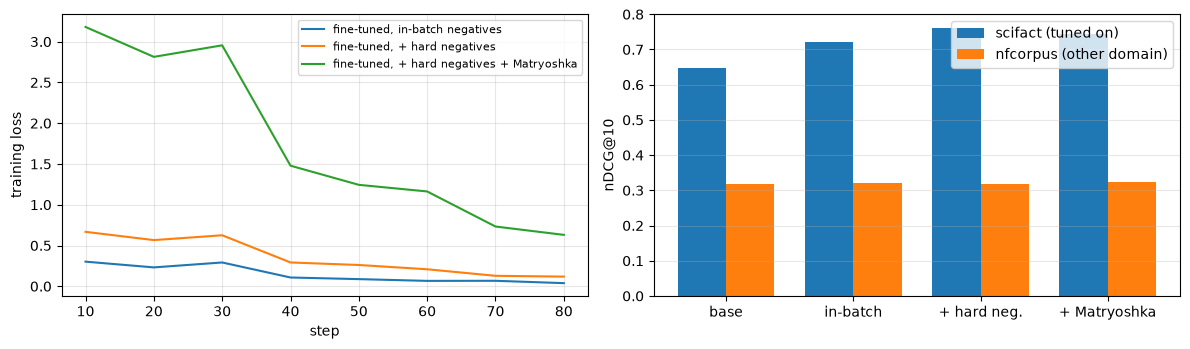

In [6]:
import tempfile, contextlib, io
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.training_args import BatchSamplers

rng = random.Random(0); rows = []
for q, rel in sci["train"].items():
    scores = bm25["scifact"].get_scores(tok(sci["queries"][q]))
    hard = [i for i in np.argsort(-scores)[:20] if sci["ids"][i] not in rel][:10]   # lexically close, but not relevant
    for d in rel:
        rows.append({"anchor": sci["queries"][q], "positive": sci["docs"][sci["pos"][d]], "negative": sci["docs"][rng.choice(hard)]})
print(f"{len(rows)} training rows | example hard negative for '{rows[0]['anchor']}':\n   {rows[0]['negative'][:200]}...")

def finetune(columns, matryoshka=False, epochs=3):
    torch.manual_seed(0)
    model = SentenceTransformer(NAME, device=device)
    loss = losses.MultipleNegativesRankingLoss(model)
    if matryoshka:
        loss = losses.MatryoshkaLoss(model, loss, matryoshka_dims=[384, 256, 128, 64])
    args = SentenceTransformerTrainingArguments(
        output_dir=os.path.join(tempfile.gettempdir(), "llm_edu_21"), num_train_epochs=epochs, per_device_train_batch_size=32,
        learning_rate=5e-5, warmup_steps=0.1, bf16=device == "cuda", batch_sampler=BatchSamplers.NO_DUPLICATES,
        report_to="none", save_strategy="no", logging_steps=10, seed=0, disable_tqdm=True)
    data = Dataset.from_list([{k: r[k] for k in columns} for r in rows])
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # keep the trainer's step logs out of the notebook
        trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=data, loss=loss)
        t0 = time.time(); trainer.train()
    curve = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    return model, time.time() - t0, curve

MODELS, CURVES = {}, {}
for tag, cols, mat in [("fine-tuned, in-batch negatives", ["anchor", "positive"], False),
                       ("fine-tuned, + hard negatives", ["anchor", "positive", "negative"], False),
                       ("fine-tuned, + hard negatives + Matryoshka", ["anchor", "positive", "negative"], True)]:
    model, secs, CURVES[tag] = finetune(cols, mat)
    MODELS[tag] = model
    Q, D, _, _ = st_embed(model, sci)
    EMB[("scifact", tag)] = (Q, D)
    report(tag, search(Q, D), train_s=f"{secs:.0f}")

base = SentenceTransformer(NAME, device=device)
for tag, model in [("all-MiniLM-L6-v2", base)] + list(MODELS.items()):
    Q, D, _, _ = st_embed(model, nfc)
    report(tag, search(Q, D), ds=nfc)
del base; free()

for tag in MODELS:
    d, lo, hi = paired_bootstrap_diff(RUNS[("scifact", "all-MiniLM-L6-v2")]["ndcg"], RUNS[("scifact", tag)]["ndcg"])
    d2, lo2, hi2 = paired_bootstrap_diff(RUNS[("nfcorpus", "all-MiniLM-L6-v2")]["ndcg"], RUNS[("nfcorpus", tag)]["ndcg"])
    print(f"  {tag:42s} vs base: SciFact {d:+.3f} [{lo:+.3f}, {hi:+.3f}] | NFCorpus {d2:+.3f} [{lo2:+.3f}, {hi2:+.3f}]")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for tag, curve in CURVES.items():
    ax[0].plot(*zip(*curve), label=tag)
ax[0].set_xlabel("step"); ax[0].set_ylabel("training loss"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
labels = ["all-MiniLM-L6-v2"] + list(MODELS)
x = np.arange(len(labels)); w = 0.38
for k, (dsn, c) in enumerate([("scifact", "tab:blue"), ("nfcorpus", "tab:orange")]):
    ax[1].bar(x + (k - 0.5) * w, [RUNS[(dsn, n)]["ndcg"].mean() for n in labels], w, color=c, label=dsn + (" (tuned on)" if k == 0 else " (other domain)"))
ax[1].set_xticks(x, ["base", "in-batch", "+ hard neg.", "+ Matryoshka"]); ax[1].set_ylabel("nDCG@10"); ax[1].legend(); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

**What the numbers say.**

- **Fine-tuning pays, and quickly.** In-batch negatives alone lift MiniLM from 0.648 to 0.723 (+0.074 [+0.050, +0.101]) in 13 s of training. One BM25-mined hard negative per pair lifts it to **0.762** (+0.114 [+0.086, +0.145]) in 22 s. That beats both modern off-the-shelf models (0.706 and 0.708) with a 22M-parameter model and 919 labelled pairs. Hard negatives teach what in-batch negatives cannot: to separate the relevant abstract from one that uses the same words.
- **It did not hurt the other domain.** On NFCorpus every fine-tuned model stays within ±0.005 of the base model (0.319), with intervals that include zero. Three epochs at a small learning rate moved the model toward scientific claims without erasing its general knowledge. Longer training or a higher learning rate can do damage, which is why the check belongs in every fine-tuning run.
- **The Matryoshka loss costs a little at full size** (0.745 against 0.762): part of the training signal goes to making the short prefixes good. Section 4 shows what that buys.
- The training curves fall smoothly. The Matryoshka loss is about four times larger because it is a sum over four prefix lengths.

A fine-tuned small model beating a larger general one is the norm, not the exception, when you have even a few hundred labelled queries from your own domain.

## 4. Smaller vectors: Matryoshka truncation and quantization

### 4.1 Truncating dimensions

We keep the first $m$ dimensions of every vector, renormalize, and search again. The base MiniLM; nomic as Ollama serves it, and with the layer norm its model card applies before truncating; and our two hard-negative models, one trained with the Matryoshka loss and one without. Same data, same steps, so the comparison isolates the loss.

all-MiniLM-L6-v2 (base)                    384d 0.648  256d 0.641  128d 0.601  64d 0.491  32d 0.340
nomic-embed-text (as served)               768d 0.708  512d 0.702  256d 0.676  128d 0.645  64d 0.534  32d 0.365


nomic-embed-text + layer norm (its recipe) 768d 0.708  512d 0.702  256d 0.676  128d 0.646  64d 0.536  32d 0.365
fine-tuned + hard negatives                384d 0.762  256d 0.750  128d 0.698  64d 0.589  32d 0.367


fine-tuned + hard negatives + Matryoshka   384d 0.745  256d 0.756  128d 0.718  64d 0.646  32d 0.434


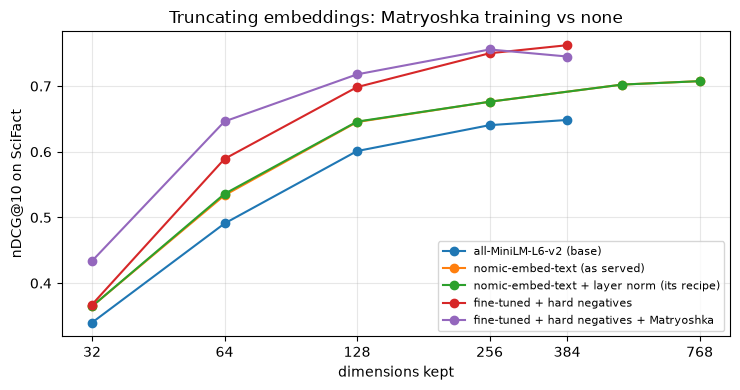

In [7]:
def truncated(Q, D, m):
    return F.normalize(torch.as_tensor(Q[:, :m]), dim=1).numpy(), F.normalize(torch.as_tensor(D[:, :m]), dim=1).numpy()

# nomic's documented Matryoshka recipe applies a layer norm *before* truncating. Layer norm is scale-invariant,
# so applying it to Ollama's already L2-normalized vectors is the same as applying it to the raw ones.
Qn_, Dn_ = EMB[("scifact", "nomic")]
EMB[("scifact", "nomic-ln")] = tuple(F.layer_norm(torch.as_tensor(X), (X.shape[1],)).numpy() for X in (Qn_, Dn_))

TRUNC = {}
for label, key, dims in [("all-MiniLM-L6-v2 (base)", "sentence-transformers/all-MiniLM-L6-v2", [384, 256, 128, 64, 32]),
                         ("nomic-embed-text (as served)", "nomic", [768, 512, 256, 128, 64, 32]),
                         ("nomic-embed-text + layer norm (its recipe)", "nomic-ln", [768, 512, 256, 128, 64, 32]),
                         ("fine-tuned + hard negatives", "fine-tuned, + hard negatives", [384, 256, 128, 64, 32]),
                         ("fine-tuned + hard negatives + Matryoshka", "fine-tuned, + hard negatives + Matryoshka", [384, 256, 128, 64, 32])]:
    Q, D = EMB[("scifact", key)]
    TRUNC[label] = {m: per_query(search(*truncated(Q, D, m)), sci)[0].mean() for m in dims}
    print(f"{label:42s} " + "  ".join(f"{m}d {v:.3f}" for m, v in TRUNC[label].items()))

fig, ax = plt.subplots(figsize=(7.5, 4))
for label, curve in TRUNC.items():
    ax.plot(list(curve), list(curve.values()), "o-", label=label)
ax.set_xscale("log", base=2); ax.set_xticks([32, 64, 128, 256, 384, 768], ["32", "64", "128", "256", "384", "768"])
ax.set_xlabel("dimensions kept"); ax.set_ylabel("nDCG@10 on SciFact"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Truncating embeddings: Matryoshka training vs none")
plt.tight_layout(); plt.show()

**What the numbers say.** Same data, same steps, only the loss differs:

| dimensions | base MiniLM | nomic as served | nomic + layer norm | fine-tuned | fine-tuned + Matryoshka |
|---|---|---|---|---|---|
| full (384 / 768) | 0.648 | 0.708 | 0.708 | **0.762** | 0.745 |
| 256 | 0.641 | 0.676 | 0.676 | 0.750 | **0.756** |
| 128 | 0.601 | 0.645 | 0.646 | 0.698 | **0.718** |
| 64 | 0.491 | 0.534 | 0.536 | 0.589 | **0.646** |
| 32 | 0.340 | 0.365 | 0.365 | 0.367 | **0.434** |

- **Below 256 dimensions the Matryoshka model wins at every size**, and the gap grows as vectors shrink: +0.020 at 128, +0.057 at 64, +0.067 at 32. At 64 dimensions (6× smaller vectors) it keeps 87 % of the full model's score, against 77 % without the loss. At 256 it is even slightly *above* its own full-size score, because the loss concentrated the useful information in the first dimensions.
- **nomic-embed-text, as served by Ollama, loses about as much as plain MiniLM when truncated** (−25 % at 64 dimensions, against −24 % for MiniLM). nomic-embed-text v1.5 is documented as Matryoshka-trained, and its recipe applies a layer norm before truncating. We tested that explanation, and it is not the cause: with the layer norm the curve does not move (0.536 against 0.534 at 64 dimensions). From here we cannot tell which weights or conversion Ollama serves under this tag. The practical lesson stands: measure truncation on the exact model and serving path you will deploy, because a model card's claim may not survive your pipeline.

The choice is a dial: keep 256 dimensions of the Matryoshka model and lose nothing, or 64 and keep almost 90 %.

### 4.2 Quantizing: int8 and binary, with rescoring

On the best model (hard negatives, 384 dimensions) we store the document vectors as int8 (one byte per dimension, calibrated on the corpus) and as single bits, with `sentence_transformers.quantization.quantize_embeddings`. Binary search uses the Hamming distance; **rescoring** then takes the top 100 binary candidates and reorders them with the float *query* against the int8 documents, so the float corpus never has to be kept in memory.

In [8]:
from sentence_transformers.quantization import quantize_embeddings
Q, D = EMB[("scifact", "fine-tuned, + hard negatives")]
D8 = quantize_embeddings(D, precision="int8", calibration_embeddings=D)
Q8 = quantize_embeddings(Q, precision="int8", calibration_embeddings=D)
Db = quantize_embeddings(D, precision="ubinary"); Qb = quantize_embeddings(Q, precision="ubinary")   # 384 bits -> 48 bytes
print(f"bytes per document vector: float32 {D[0].nbytes}, int8 {D8[0].nbytes}, binary {Db[0].nbytes}")

def hamming_top(Qb, Db, k=100):
    bits_q, bits_d = np.unpackbits(Qb, axis=1).astype(np.float32), np.unpackbits(Db, axis=1).astype(np.float32)
    # Hamming distance = number of differing bits; on +-1 codes it is a linear function of the dot product
    s = torch.as_tensor(2 * bits_q - 1, device=device) @ torch.as_tensor(2 * bits_d - 1, device=device).T
    return torch.topk(s, k, dim=1).indices.cpu().numpy()

t0 = time.time(); top_f = search(Q, D); t_f = time.time() - t0
report("float32 (1,536 bytes/doc)", top_f)
top_8 = np.argsort(-(Q8.astype(np.int32) @ D8.astype(np.int32).T), axis=1)[:, :100]
report("int8 (384 bytes/doc)", top_8)
top_b = hamming_top(Qb, Db)
report("binary (48 bytes/doc)", top_b)
D8f = D8.astype(np.float32)
top_br = np.array([row[np.argsort(-(D8f[row] @ Q[i]))] for i, row in enumerate(top_b)])
report("binary + int8 rescoring of the top 100", top_br)

print("\nmemory for the document vectors of 100 million documents:")
for label, b in [("float32, 768 dims (nomic)", 768 * 4), ("float32, 384 dims", 384 * 4), ("int8, 384 dims", 384), ("binary, 384 dims", 48),
                 ("binary 384 + int8 384 on disk for rescoring", 48)]:
    print(f"  {label:44s} {b * 1e8 / 1e9:7.1f} GB in RAM")

bytes per document vector: float32 1536, int8 384, binary 48
scifact  float32 (1,536 bytes/doc)                nDCG@10 0.762 [0.723, 0.800] | recall@100 0.956


scifact  int8 (384 bytes/doc)                     nDCG@10 0.752 [0.712, 0.789] | recall@100 0.959
scifact  binary (48 bytes/doc)                    nDCG@10 0.709 [0.664, 0.750] | recall@100 0.934
scifact  binary + int8 rescoring of the top 100   nDCG@10 0.760 [0.721, 0.799] | recall@100 0.934

memory for the document vectors of 100 million documents:
  float32, 768 dims (nomic)                      307.2 GB in RAM
  float32, 384 dims                              153.6 GB in RAM
  int8, 384 dims                                  38.4 GB in RAM
  binary, 384 dims                                 4.8 GB in RAM
  binary 384 + int8 384 on disk for rescoring      4.8 GB in RAM


**What the numbers say.**

- **int8** (4× smaller than float32) costs 0.010 (0.752 against 0.762).
- **Binary** (32× smaller, 48 bytes per document) costs 0.053 on its own (0.709), but its recall@100 stays at 0.934: the right documents are still in the candidate list, just in the wrong order.
- **Rescoring fixes the order.** The float query against int8 vectors of the 100 binary candidates gives **0.760**, within the noise of float32 (0.762). The recall is the binary one (0.934), since rescoring only reorders.

For 100 million documents, that is the difference between 154 GB of float32 vectors in RAM and 4.8 GB of binary codes in RAM, with int8 vectors on disk read only for the 100 candidates of each query. This is the recipe vector databases implement (binary or product quantization plus rescoring), and quantization combines with Matryoshka truncation for further savings.

## 5. Hybrid retrieval and rerankers

The first stage now combines BM25 and the fine-tuned dense model with **reciprocal rank fusion** (RRF, notebook 18): each document scores $\sum 1/(60 + \text{rank})$ over the two lists. Then two cross-encoders rerank the top candidates:

- **ms-marco-MiniLM-L6-v2** (22M parameters): trained on MS MARCO, Bing web-search queries. Small and fast, and the most downloaded reranker on the Hub.
- **bge-reranker-base** (278M, BAAI): a larger cross-encoder trained on a broader mix of retrieval data.

Each reranker scores the top 50 candidates of every query once. We then measure reranking only the top 10, 20 or 50, because the depth is the main latency knob: a cross-encoder's cost grows linearly with the number of candidates it reads.

scifact  hybrid: BM25 + fine-tuned (RRF)          nDCG@10 0.735 [0.693, 0.774] | recall@100 0.973


scifact  hybrid: BM25 + nomic (RRF)               nDCG@10 0.707 [0.663, 0.749] | recall@100 0.955


scifact  hybrid + ms-marco-MiniLM-L6-v2 @ top 10  nDCG@10 0.700 [0.657, 0.741] | recall@100 0.973 | ms_per_query 61
scifact  hybrid + ms-marco-MiniLM-L6-v2 @ top 20  nDCG@10 0.693 [0.649, 0.734] | recall@100 0.973 | ms_per_query 123
scifact  hybrid + ms-marco-MiniLM-L6-v2 @ top 50  nDCG@10 0.692 [0.649, 0.734] | recall@100 0.973 | ms_per_query 307


scifact  hybrid + bge-reranker-base @ top 10      nDCG@10 0.722 [0.680, 0.763] | recall@100 0.973 | ms_per_query 333
scifact  hybrid + bge-reranker-base @ top 20      nDCG@10 0.731 [0.690, 0.771] | recall@100 0.973 | ms_per_query 667
scifact  hybrid + bge-reranker-base @ top 50      nDCG@10 0.725 [0.684, 0.764] | recall@100 0.973 | ms_per_query 1667


  ms-marco-MiniLM-L6-v2 @ top 50 vs no reranker: -0.042 [-0.072, -0.013]
  bge-reranker-base @ top 50 vs no reranker: -0.009 [-0.038, +0.018]


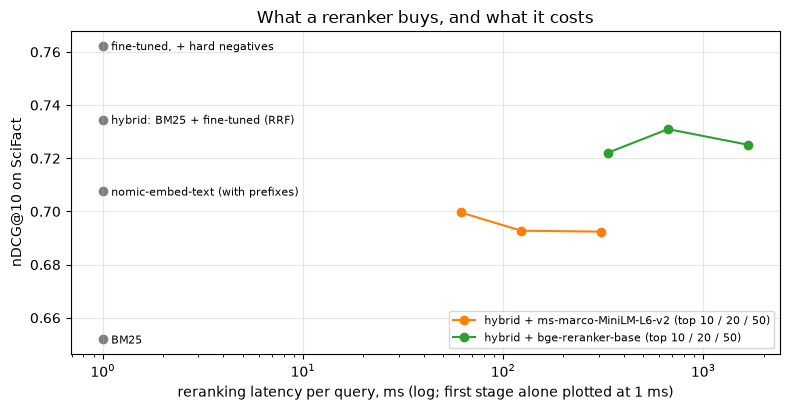

In [9]:
def rrf(*tops, k=60, n=100):
    out = []
    for rows in zip(*tops):
        score = {}
        for row in rows:
            for r, d in enumerate(row):
                score[int(d)] = score.get(int(d), 0) + 1 / (k + r + 1)
        out.append(sorted(score, key=lambda d: -score[d])[:n])
    return np.array(out)

dense_best = RUNS[("scifact", "fine-tuned, + hard negatives")]["top"]
top_hybrid = rrf(top_bm25, dense_best)
report("hybrid: BM25 + fine-tuned (RRF)", top_hybrid)
report("hybrid: BM25 + nomic (RRF)", rrf(top_bm25, RUNS[("scifact", "nomic-embed-text (with prefixes)")]["top"]))

RERANK = {}
for name in ["cross-encoder/ms-marco-MiniLM-L6-v2", "BAAI/bge-reranker-base"]:
    ce = CrossEncoder(name, device=device)
    t0 = time.time()
    scores = [ce.predict([(sci["qtexts"][i], sci["docs"][d]) for d in row[:50]], batch_size=50) for i, row in enumerate(top_hybrid)]
    ms50 = 1000 * (time.time() - t0) / len(top_hybrid)
    short = name.split("/")[1]
    for depth in [10, 20, 50]:
        top = np.array([list(row[:depth][np.argsort(-s[:depth])]) + list(row[depth:]) for row, s in zip(top_hybrid, scores)])
        ms = ms50 * depth / 50                                   # cost is linear in the number of (query, document) pairs
        RERANK[(short, depth)] = ms
        report(f"hybrid + {short} @ top {depth}", top, ms_per_query=f"{ms:.0f}")
    del ce; free()

for short in ["ms-marco-MiniLM-L6-v2", "bge-reranker-base"]:
    d, lo, hi = paired_bootstrap_diff(RUNS[("scifact", "hybrid: BM25 + fine-tuned (RRF)")]["ndcg"], RUNS[("scifact", f"hybrid + {short} @ top 50")]["ndcg"])
    print(f"  {short} @ top 50 vs no reranker: {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")

fig, ax = plt.subplots(figsize=(8, 4.2))
first = {n: RUNS[("scifact", n)]["ndcg"].mean() for n in ["BM25", "nomic-embed-text (with prefixes)", "fine-tuned, + hard negatives", "hybrid: BM25 + fine-tuned (RRF)"]}
for n, v in first.items():
    ax.scatter(1, v, color="tab:gray"); ax.annotate(n, (1, v), textcoords="offset points", xytext=(6, -3), fontsize=8)
for short, c in [("ms-marco-MiniLM-L6-v2", "tab:orange"), ("bge-reranker-base", "tab:green")]:
    xs = [RERANK[(short, d)] for d in [10, 20, 50]]; ys = [RUNS[("scifact", f"hybrid + {short} @ top {d}")]["ndcg"].mean() for d in [10, 20, 50]]
    ax.plot(xs, ys, "o-", color=c, label=f"hybrid + {short} (top 10 / 20 / 50)")
ax.set_xscale("log"); ax.set_xlabel("reranking latency per query, ms (log; first stage alone plotted at 1 ms)"); ax.set_ylabel("nDCG@10 on SciFact")
ax.grid(alpha=.3); ax.legend(fontsize=8, loc="lower right"); ax.set_title("What a reranker buys, and what it costs")
plt.tight_layout(); plt.show()

**What the numbers say.** This section did not go as the textbook says, and that is the lesson.

- **Hybrid retrieval hurt the fine-tuned model.** RRF with BM25 drops nDCG@10 from 0.762 to 0.735, although it raises recall@100 to 0.973, the highest of the notebook. RRF weighs both lists equally, and BM25 (0.652) is now much worse than the dense model, so it pulls good documents down the top 10. With nomic, which is close to BM25, hybrid changes nothing (0.707 against 0.708). Hybrid search helps when the two retrievers are comparable and make different mistakes, as in notebook 18, not by default.
- **The most downloaded reranker made things worse.** ms-marco-MiniLM reranking the hybrid list scores 0.692 at depth 50, −0.042 [−0.072, −0.013] against no reranker. It was trained on short web-search queries and passages, and scientific claims against abstracts are a different task. This is a domain mismatch, and it is common.
- **bge-reranker-base is better but still does not beat the fine-tuned bi-encoder.** Its best is 0.731 at depth 20, and at depth 50 it is −0.009 [−0.038, +0.018] against the hybrid list, a tie. All of that costs 0.3–1.7 s per query on this GPU, against under 1 ms for the bi-encoder.
- **Deeper is not always better.** Both rerankers peak at 10–20 candidates. Reading more candidates lets them promote more of their own mistakes.

Rerankers usually help when the first stage is a general model. Here, the first stage had already been fine-tuned on in-domain data with hard negatives, and a general reranker had nothing to add. The production rule: evaluate the reranker against your *best* first stage, on your own queries. If it is general-purpose and you have labels, fine-tune it too: a cross-encoder trains with the same hard negatives (`CrossEncoderTrainer` in `sentence-transformers`).

## Results

| question | best answer on SciFact (300 test claims, 5,183 abstracts) | lesson |
|---|---|---|
| off-the-shelf models | bge-small 0.706, nomic 0.708 vs BM25 0.652 nDCG@10; MiniLM 0.648 | modern small models beat BM25; old ones do not |
| task prefixes (nomic) | +0.006, within the noise on this task | cheap to get right, always use them |
| InfoNCE | by hand = `MultipleNegativesRankingLoss` (0.18594) | the loss is a cross-entropy over the batch |
| contrastive fine-tuning, 919 pairs | 0.648 → 0.723 (in-batch) → **0.762** (+ BM25 hard negatives), 22 s of training | a few hundred in-domain labels beat a bigger general model |
| other domain (NFCorpus) | within ±0.005 of the base model | no forgetting at this training budget; always check |
| Matryoshka loss | 64 dims: 0.646 vs 0.589 without it; 256 dims: 0.756 (≥ full size) | trains a dial between quality and vector size |
| quantization | binary + int8 rescoring 0.760 vs float32 0.762; 48 vs 1,536 bytes per document | 32× less RAM at no measurable cost |
| hybrid + rerankers | hybrid 0.735 (recall@100 0.973); ms-marco reranker 0.692; bge-reranker 0.731 at best, 0.3–1.7 s/query | general rerankers can lose to a fine-tuned bi-encoder |

What this establishes: retrieval quality is decided by measurement on your own queries, not by leaderboards or default pipelines. On this task, the best system is the cheapest one: a 22M-parameter bi-encoder fine-tuned for 22 seconds, stored as binary codes with int8 rescoring, with no reranker.

## In production

**Choosing and building the retriever.**
- Build a labelled set of real queries first: even 100–300 queries with their relevant documents. Label them from logs, from user clicks, or with an LLM judge checked by hand (notebook 18).
- Measure BM25, two or three embedding models from MTEB in your size and latency budget, and hybrid retrieval, all with nDCG@10 and recall@100 and with paired intervals.
- With a few hundred labelled pairs, fine-tune: `sentence-transformers` with `MultipleNegativesRankingLoss`, hard negatives mined with BM25 or the current model, and `BatchSamplers.NO_DUPLICATES`. Use `MatryoshkaLoss` if you may want smaller vectors later.
- Check a general set before and after, to catch forgetting.
- Watch for false negatives in mined hard negatives (unlabelled documents that are actually relevant). Filtering candidates by a reranker score threshold is the standard fix.

**Serving.**
- Encode documents offline, in batches, and version the vectors together with the model that produced them. Changing the model means re-encoding the whole corpus, so plan for it.
- Store vectors in a vector index: FAISS, or a database (pgvector, Qdrant, Weaviate, Milvus, Elasticsearch / OpenSearch). Use HNSW or IVF for approximate search at scale, and binary or int8 quantization with rescoring.
- Encode queries in-process for small models, or behind an embedding server (TEI, Infinity, Ollama, a provider API) for large ones.
- Add a reranker only if it beats your best first stage on your labels. Then cap its depth (10–20 here) and its latency, and consider fine-tuning it (`CrossEncoderTrainer`) or using an LLM reranker for low-volume, high-value queries.

**What to monitor.**
- nDCG@10 and recall@k on a frozen labelled set at every model, index or chunking change.
- Online signals: clicks, "no result" rate, answer groundedness in RAG.
- Query latency (p50 / p95) for the encoder, the index and the reranker separately.
- Index size and memory.
- Query drift: new vocabulary or new kinds of questions that the labelled set does not cover.

**Failure modes.**
- Missing or wrong task prefixes.
- Query and document vectors from different model versions (after a partial re-index).
- Unnormalized vectors with a cosine index.
- Truncating a model not trained for it.
- A reranker from the wrong domain.
- Hybrid fusion that lets a weak retriever drag a strong one down.
- Trusting MTEB rank over your own evaluation.

**Next:** `18_rag.ipynb`, which puts these components into a full retrieval-augmented generation pipeline.